In [2]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import transpile
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit_aer import AerSimulator

from benchmark.fermionic_hea import make_fermionic_hea, get_smooth_params
from benchmark.models2 import build_noise_model, get_ibm_kingston_backend

from sv import make_fermionic_h2_sv
from zne import ZNEMitigator, fold_gates_local, richardson_extrapolation
from mem import MEMitigator
from pc_vd import VDMitigator
from pec2 import PECMitigator  # retained for the existing experimental combinations
from pec_fermionic import (
    PECMitigator as FermionicPECMitigator,
    run_hamiltonian_pec,
)
from senew import SEMitigator, default_single_qubit_pool
from nrep import (
    NRepMitigator, get_h2_sto3g_hamiltonian, jw_annihilation,
    project_rdms_sdp, energy_general, rdm_operators
)

N_QUBITS, N_ELECTRONS = 4, 2
DEPTHS = [2,4,6,8]    #[2, 4, 6, 8, 10]
PARAMETER_SEED = 42
ZNE_SHOTS, MEM_SHOTS, NREP_SHOTS = 8192, 8192, 30000

PEC_NUM_SAMPLES = 1000
PEC_SHOTS_PER_SAMPLE = 4
PEC_NOISY_SHOTS = 8192
PEC_SEED = 42
PEC_BASIS_GATES = ["x", "rx", "ry", "rz", "cx"]


RUN_STANDALONE = {
    "ZNE": True,
    "MEM": True,
    "VD": True,
    "SE": True,
    "NRep": True,
    "PEC": False,        # Full-H2 PEC through pec_fermionic.py
    "SV": True,        # Not yet implemented as a full-H2 adapter
    "Learning": False   # No learning-based implementation supplied
}

RUN_COMBINATIONS = {
    "SE + NRep": True,
    "ZNE + NRep": True,
    "MEM + NRep": True,
    "MEM + SE + NRep": True,
    "MEM + VD + NRep": True,
    "SV + SE + NRep": True,
    "MEM + SV + NRep": True,
    "ZNE + MEM + SE": True,
    "ZNE + MEM + NRep": True,
    "PEC + MEM + NRep": False,
    "PEC + SE + NRep": False,
    "VD + SE + NRep": True,
    "ZNE + PEC + MEM": False
}

ENABLED_COMBINATIONS = {
    name for name, enabled in RUN_COMBINATIONS.items() if enabled
}

SHOW_EXECUTION_PLAN = True

IBM_BACKEND_NAME = "ibm_kingston"
IBM_BACKEND = get_ibm_kingston_backend()
print(
    f"Using calibration snapshot from {IBM_BACKEND.name} "
    f"({IBM_BACKEND.num_qubits} physical qubits)"
)
noise_model = build_noise_model(
    "combined",
    backend=IBM_BACKEND
)

COLORS = {
    "Ideal":"green", "Noisy":"black", "PEC":"deepskyblue", "ZNE":"blue", "MEM":"red",
    "VD":"magenta", "SV":"olive", "SE":"cyan", "NRep":"brown",
    "SE + NRep":"purple", "ZNE + NRep":"darkgreen", "MEM + NRep":"darkred",
    "MEM + SE + NRep":"darkorange",
    "MEM + VD + NRep":"olive",
    "SV + SE + NRep":"teal",
    "MEM + SV + NRep":"coral",
    "ZNE + MEM + SE":"slateblue",
    "ZNE + MEM + NRep":"goldenrod",
    "PEC + MEM + NRep":"maroon",
    "PEC + SE + NRep":"darkcyan",
    "VD + SE + NRep":"orchid",
    "ZNE + PEC + MEM":"saddlebrown"
}

Using calibration snapshot from ibm_kingston (156 physical qubits)


In [3]:
METHOD_NAMES = ["ZNE", "MEM", "PEC", "VD", "SV", "SE", "NRep", "Learning"]

ALL_COMBINATIONS = {}
for size in range(2, len(METHOD_NAMES) + 1):
    for subset in itertools.combinations(METHOD_NAMES, size):
        name = " + ".join(subset)
        ALL_COMBINATIONS[name] = list(subset)

combination_catalogue = pd.DataFrame([
    {"combination": name, "number_of_methods": len(methods),
     "methods": " → ".join(methods)}
    for name, methods in ALL_COMBINATIONS.items()
])

print(f"Candidate combinations generated: {len(ALL_COMBINATIONS)}")
display(combination_catalogue)

Candidate combinations generated: 247


,combination,number_of_methods,methods
0,ZNE + MEM,2,ZNE → MEM
1,ZNE + PEC,2,ZNE → PEC
2,ZNE + VD,2,ZNE → VD
3,ZNE + SV,2,ZNE → SV
4,ZNE + SE,2,ZNE → SE
...,...,...,...
242,ZNE + MEM + PEC + SV + SE + NRep + Learning,7,ZNE → MEM → PEC → SV → SE → NRep → Learning
243,ZNE + MEM + VD + SV + SE + NRep + Learning,7,ZNE → MEM → VD → SV → SE → NRep → Learning
244,ZNE + PEC + VD + SV + SE + NRep + Learning,7,ZNE → PEC → VD → SV → SE → NRep → Learning
245,MEM + PEC + VD + SV + SE + NRep + Learning,7,MEM → PEC → VD → SV → SE → NRep → Learning


In [4]:
h1, g2, e_nuc = get_h2_sto3g_hamiltonian()

def build_h2_hamiltonian(n=4):
    a = jw_annihilation(n)
    adag = [op.conj().T for op in a]
    Hmat = np.zeros((2**n, 2**n), dtype=complex)
    for p in range(n):
        for q in range(n):
            Hmat += h1[p,q] * adag[p] @ a[q]
    for p in range(n):
        for q in range(n):
            for r in range(n):
                for s in range(n):
                    Hmat += 0.5*g2[p,q,r,s]*adag[p]@adag[q]@a[s]@a[r]
    Hmat += e_nuc*np.eye(2**n)
    Hmat = (Hmat + Hmat.conj().T)/2
    return SparsePauliOp.from_operator(Operator(Hmat)).simplify()

H2 = build_h2_hamiltonian(N_QUBITS)

def count_gates(qc):
    return sum(inst.operation.name != "barrier" for inst in qc.data)

circuits, gate_counts = {}, {}
for depth in DEPTHS:
    qcp = make_fermionic_hea(
        num_qubits=N_QUBITS, nelec=N_ELECTRONS, layers=depth
    )
    params = get_smooth_params(qcp, layer_depth=depth, seed=PARAMETER_SEED)
    circuits[depth] = qcp.assign_parameters(params)
    gate_counts[depth] = count_gates(circuits[depth])
    print(f"layers={depth}, gates={gate_counts[depth]}, depth={circuits[depth].depth()}")

layers=2, gates=38, depth=25
layers=4, gates=74, depth=49
layers=6, gates=110, depth=73
layers=8, gates=146, depth=97


In [5]:
def noisy_density_matrix(circuit):
    backend = AerSimulator(method="density_matrix", noise_model=noise_model)
    tqc = transpile(circuit, backend, optimization_level=0)
    tqc.save_density_matrix()
    return np.asarray(backend.run(tqc).result().data(0)["density_matrix"])

def perform_se_expansion(circuit, observable, operator_pool, cutoff=1e-6):
    n = circuit.num_qubits
    pool = [SparsePauliOp.from_list([("I"*n, 1.0)])] + list(operator_pool)
    mats = [p.to_matrix() for p in pool]
    rho = noisy_density_matrix(circuit)
    Hmat = observable.to_matrix()
    k = len(pool)
    S, Hs = np.zeros((k,k),complex), np.zeros((k,k),complex)
    for i, Pi in enumerate(mats):
        for j, Pj in enumerate(mats):
            S[i,j] = np.trace(rho @ Pi.conj().T @ Pj)
            Hs[i,j] = np.trace(rho @ Pi.conj().T @ Hmat @ Pj)
    S, Hs = (S+S.conj().T)/2, (Hs+Hs.conj().T)/2
    sv, U = np.linalg.eigh(S)
    order = np.argsort(sv)[::-1]
    sv, U = sv[order], U[:,order]
    keep = sv > cutoff*max(float(sv[0]),1e-300)
    if not np.any(keep):
        raise RuntimeError("SE overlap matrix has no retained directions")
    X = U[:,keep] @ np.diag(1/np.sqrt(sv[keep]))
    Hp = X.conj().T @ Hs @ X
    Hp = (Hp+Hp.conj().T)/2
    evals, evecs = np.linalg.eigh(Hp)
    idx = int(np.argmin(evals))
    coeff = X @ evecs[:,idx]
    A = sum(coeff[i]*mats[i] for i in range(k))
    rho_se = A @ rho @ A.conj().T
    tr = np.trace(rho_se).real
    if tr <= 1e-12:
        raise RuntimeError("SE expanded state has nonpositive trace")
    rho_se /= tr
    return {"rho_se":(rho_se+rho_se.conj().T)/2,
            "se_energy":float(evals[idx].real)}

In [6]:
def calibrate_mem():
    obj = MEMitigator(num_qubits=N_QUBITS, shots=MEM_SHOTS)
    obj.calibrate(AerSimulator(noise_model=noise_model))
    A = np.array([[1.0]])
    for q in reversed(range(N_QUBITS)):
        A = np.kron(A, obj.calibration_matrices[q])
    return obj, A, np.linalg.pinv(A)

MEM_NEEDED = (
    RUN_STANDALONE.get("MEM", False)
    or any("MEM" in name for name in ENABLED_COMBINATIONS)
)
if MEM_NEEDED:
    mem_obj, A_readout, A_readout_inv = calibrate_mem()
else:
    mem_obj, A_readout, A_readout_inv = None, None, None

def pauli_basis_probabilities(rho, label):
    Hgate = np.array([[1,1],[1,-1]],complex)/np.sqrt(2)
    Sdg = np.diag([1,-1j])
    I2 = np.eye(2,dtype=complex)
    local=[]
    for p in label:
        local.append(I2 if p in "IZ" else Hgate if p=="X" else Hgate@Sdg)
    U=local[0]
    for u in local[1:]:
        U=np.kron(U,u)
    probs=np.real(np.diag(U@rho@U.conj().T))
    probs=np.clip(probs,0,None)
    return probs/probs.sum()

def estimate_pauli(rho,label,shots,rng,use_mem):
    if set(label) <= {"I"}:
        return 1.0
    probs=pauli_basis_probabilities(rho,label)
    if use_mem:
        probs=A_readout@probs
    probs=np.clip(probs,0,None); probs=probs/probs.sum()
    counts=rng.multinomial(shots,probs)
    p_est=counts/shots
    if use_mem:
        p_est=A_readout_inv@p_est
    ev=0.0
    for idx,prob in enumerate(p_est):
        bits=format(idx,f"0{len(label)}b")
        eig=1
        for bit,p in zip(bits,label):
            if p!="I" and bit=="1":
                eig *= -1
        ev += eig*prob
    return float(np.real(ev))

def reconstruct_rdms(rho,shots,seed=42,use_mem=False):
    n=N_QUBITS
    rng=np.random.default_rng(seed)
    O1,O2=rdm_operators(n)
    decs=[]; labels=set()
    for kind,ops in [("1",O1),("2",O2)]:
        for key,op in ops.items():
            spo=SparsePauliOp.from_operator(Operator(op.toarray())).simplify()
            terms=[(lab,c) for lab,c in zip(spo.paulis.to_labels(),spo.coeffs)
                   if abs(c)>1e-12]
            decs.append((kind,key,terms))
            labels.update(lab for lab,_ in terms)
    estimates={lab:estimate_pauli(rho,lab,shots,rng,use_mem) for lab in labels}
    D1=np.zeros((n,n),complex)
    D2t=np.zeros((n,n,n,n),complex)
    for kind,key,terms in decs:
        val=sum(c*estimates[lab] for lab,c in terms)
        if kind=="1":
            D1[key[0],key[1]]=val
        else:
            D2t[key[0],key[1],key[2],key[3]]=val
    return D1,D2t.reshape(n*n,n*n)

def nrep_project_energy(D1,D2):
    D1p,D2p=project_rdms_sdp(D1,D2,N_QUBITS,N_ELECTRONS,real=True)
    return energy_general(h1,g2,D1p,D2p,e_nuc)


def postselect_fixed_hamming_weight(rho, n=N_QUBITS, target=N_ELECTRONS):
    """Project a density matrix onto the computational-basis N-particle sector."""
    keep = [i for i in range(2**n) if int(i).bit_count() == target]
    P = np.zeros((2**n, 2**n), dtype=complex)
    P[keep, keep] = 1.0
    projected = P @ rho @ P
    tr = float(np.trace(projected).real)
    if tr <= 1e-12:
        raise RuntimeError("SV number-sector postselection retained zero probability.")
    return projected / tr, tr

def perform_se_from_density_matrix(rho, observable, operator_pool, cutoff=1e-6):
    """Same SE generalized eigenproblem as perform_se_expansion, but accepts rho."""
    n = N_QUBITS
    pool = [SparsePauliOp.from_list([("I"*n, 1.0)])] + list(operator_pool)
    mats = [p.to_matrix() for p in pool]
    Hmat = observable.to_matrix()
    k = len(pool)
    S, Hs = np.zeros((k,k),complex), np.zeros((k,k),complex)
    for i, Pi in enumerate(mats):
        for j, Pj in enumerate(mats):
            S[i,j] = np.trace(rho @ Pi.conj().T @ Pj)
            Hs[i,j] = np.trace(rho @ Pi.conj().T @ Hmat @ Pj)
    S, Hs = (S+S.conj().T)/2, (Hs+Hs.conj().T)/2
    vals, U = np.linalg.eigh(S)
    order = np.argsort(vals)[::-1]
    vals, U = vals[order], U[:,order]
    keep = vals > cutoff*max(float(vals[0]),1e-300)
    if not np.any(keep):
        raise RuntimeError("SE overlap matrix has no retained directions.")
    X = U[:,keep] @ np.diag(1/np.sqrt(vals[keep]))
    Hp = X.conj().T @ Hs @ X
    Hp = (Hp+Hp.conj().T)/2
    ev, vec = np.linalg.eigh(Hp)
    coeff = X @ vec[:,int(np.argmin(ev))]
    A = sum(coeff[i]*mats[i] for i in range(k))
    rho_se = A @ rho @ A.conj().T
    tr = float(np.trace(rho_se).real)
    if tr <= 1e-12:
        raise RuntimeError("SE produced a zero-trace state.")
    rho_se /= tr
    return {"rho_se":(rho_se+rho_se.conj().T)/2,
            "se_energy":float(np.min(ev).real)}

def vd_density_matrix(rho):
    """M=2 virtual-distillation density matrix used by the existing VD module."""
    rho2 = rho @ rho
    purity = float(np.trace(rho2).real)
    if purity <= 1e-12:
        raise RuntimeError("VD purity is numerically zero.")
    return rho2 / purity, purity

def _basis_rotated_circuit(qc, label):
    """Rotate a Pauli measurement into the computational basis."""
    out = qc.copy()
    for q, p in enumerate(reversed(label)):
        if p == "X":
            out.h(q)
        elif p == "Y":
            out.sdg(q)
            out.h(q)
    return out

def _pec_pauli_expectation(qc, label, noise_model, pec_obj):
    """Use PEC's I/Z estimator after rotating one Pauli string to Z basis."""
    rotated = _basis_rotated_circuit(qc, label)
    zlabel = "".join("Z" if p != "I" else "I" for p in label)
    obs = SparsePauliOp.from_list([(zlabel, 1.0)])
    return float(pec_obj.run(rotated, obs, noise_model)["mitigated_value"])

def pec_reconstruct_rdms(qc, shots, seed, use_mem, pec_obj):
    """Experimental PEC-based Pauli reconstruction of the 1- and 2-RDMs."""
    n = N_QUBITS
    O1, O2 = rdm_operators(n)
    decs, labels = [], set()
    for kind, ops in [("1", O1), ("2", O2)]:
        for key, op in ops.items():
            spo = SparsePauliOp.from_operator(Operator(op.toarray())).simplify()
            terms = [(lab, c) for lab, c in zip(spo.paulis.to_labels(), spo.coeffs)
                     if abs(c) > 1e-12]
            decs.append((kind, key, terms))
            labels.update(lab for lab, _ in terms)
    estimates = {}
    for lab in labels:
        estimates[lab] = _pec_pauli_expectation(qc, lab, noise_model, pec_obj)
    D1 = np.zeros((n,n),complex)
    D2t = np.zeros((n,n,n,n),complex)
    for kind,key,terms in decs:
        val = sum(c*estimates[lab] for lab,c in terms)
        if kind == "1":
            D1[key[0],key[1]] = val
        else:
            D2t[key[0],key[1],key[2],key[3]] = val
    if use_mem:
        avg_flip = float(np.mean([0.5*(M[0,1]+M[1,0]) for M in mem_obj.calibration_matrices]))
        denom = max(1.0 - 2.0*avg_flip, 1e-6)
        D1 = D1 / denom
        D2t = D2t / (denom**2)
    return D1, D2t.reshape(n*n,n*n)

def make_pec_experimental():
    return PECMitigator(
        num_samples=300, shots_per_sample=4, noisy_shots=2048,
        twirl=True, readout_flip_prob=0.0, seed=42,
        chunk_size=100, verbose=False
    )

def zne_extrapolate(values, scales=(1,2,3)):
    value, weights = richardson_extrapolation(
        np.asarray(scales,dtype=float), np.asarray(values,dtype=float)
    )
    return float(value), np.asarray(weights,dtype=float)

In [7]:
zne = ZNEMitigator(
    scale_factors=[1,2,3], extrapolator="richardson",
    fold_method="local", shots=ZNE_SHOTS
) if RUN_STANDALONE["ZNE"] else None

vd = VDMitigator() if RUN_STANDALONE["VD"] else None
se = SEMitigator(
    operator_pool=default_single_qubit_pool(N_QUBITS)
) if RUN_STANDALONE["SE"] else None
nrep = NRepMitigator(
    num_qubits=N_QUBITS, nelec=N_ELECTRONS,
    shots=NREP_SHOTS, seed=42
) if RUN_STANDALONE["NRep"] else None

se_pool=default_single_qubit_pool(N_QUBITS)

sv = make_fermionic_h2_sv(
    shots=8192,
    seed_simulator=42
) if RUN_STANDALONE["SV"] else None

pec_fermionic_obj = FermionicPECMitigator(
    num_samples=PEC_NUM_SAMPLES,
    shots_per_sample=PEC_SHOTS_PER_SAMPLE,
    noisy_shots=PEC_NOISY_SHOTS,
    twirl=True,
    readout_flip_prob=0.0,
    seed=PEC_SEED,
    verbose=False
) if RUN_STANDALONE["PEC"] else None

In [8]:
def run_se_nrep(qc,H):
    x=perform_se_expansion(qc,H,se_pool)
    D1,D2=reconstruct_rdms(x["rho_se"],NREP_SHOTS,seed=2100,use_mem=False)
    return {"mitigated_value":nrep_project_energy(D1,D2)}

def run_mem_nrep(qc,H):
    rho=noisy_density_matrix(qc)
    D1,D2=reconstruct_rdms(rho,NREP_SHOTS,seed=3100,use_mem=True)
    return {"mitigated_value":nrep_project_energy(D1,D2)}

def run_mem_se_nrep(qc,H):
    x=perform_se_expansion(qc,H,se_pool)
    D1,D2=reconstruct_rdms(x["rho_se"],NREP_SHOTS,seed=4100,use_mem=True)
    return {"mitigated_value":nrep_project_energy(D1,D2)}

def run_mem_vd_nrep(qc,H):
    rho=noisy_density_matrix(qc)
    rho_vd,purity=vd_density_matrix(rho)
    D1,D2=reconstruct_rdms(rho_vd,NREP_SHOTS,seed=4200,use_mem=True)
    return {"mitigated_value":nrep_project_energy(D1,D2),"purity":purity}

def run_sv_se_nrep(qc,H):
    rho=noisy_density_matrix(qc)
    rho_sv,survival=postselect_fixed_hamming_weight(rho)
    x=perform_se_from_density_matrix(rho_sv,H,se_pool)
    D1,D2=reconstruct_rdms(x["rho_se"],NREP_SHOTS,seed=4300,use_mem=False)
    return {"mitigated_value":nrep_project_energy(D1,D2),"sv_survival":survival}

def run_mem_sv_nrep(qc,H):
    rho=noisy_density_matrix(qc)
    rho_sv,survival=postselect_fixed_hamming_weight(rho)
    D1,D2=reconstruct_rdms(rho_sv,NREP_SHOTS,seed=4400,use_mem=True)
    return {"mitigated_value":nrep_project_energy(D1,D2),"sv_survival":survival}

def run_zne_mem_se(qc,H):
    scales=(1,2,3)
    energies=[]
    for scale in scales:
        folded=fold_gates_local(qc,float(scale))
        x=perform_se_expansion(folded,H,se_pool)
        D1,D2=reconstruct_rdms(x["rho_se"],NREP_SHOTS,seed=4500+scale,use_mem=True)
        energies.append(nrep_project_energy(D1,D2))
    value,weights=zne_extrapolate(energies,scales)
    return {"mitigated_value":value,"scale_energies":energies,"zne_weights":weights}

def run_zne_mem_nrep(qc,H):
    scales=(1,2,3)
    energies=[]
    for scale in scales:
        folded=fold_gates_local(qc,float(scale))
        rho=noisy_density_matrix(folded)
        D1,D2=reconstruct_rdms(rho,NREP_SHOTS,seed=4600+scale,use_mem=True)
        energies.append(nrep_project_energy(D1,D2))
    value,weights=zne_extrapolate(energies,scales)
    return {"mitigated_value":value,"scale_energies":energies,"zne_weights":weights}

def run_zne_nrep(qc,H):
    """Apply gate-folding ZNE, then reconstruct/project the RDMs with NRep.

    No MEM correction is applied in this combination.
    """
    scales=(1,2,3)
    energies=[]
    for scale in scales:
        folded=fold_gates_local(qc,float(scale))
        rho=noisy_density_matrix(folded)
        D1,D2=reconstruct_rdms(
            rho,NREP_SHOTS,seed=4650+scale,use_mem=False
        )
        energies.append(nrep_project_energy(D1,D2))
    value,weights=zne_extrapolate(energies,scales)
    return {"mitigated_value":value,"scale_energies":energies,"zne_weights":weights}

def run_pec_mem_nrep(qc,H):
    pec_obj=make_pec_experimental()
    D1,D2=pec_reconstruct_rdms(qc,NREP_SHOTS,seed=4700,use_mem=True,pec_obj=pec_obj)
    return {"mitigated_value":nrep_project_energy(D1,D2)}

def run_pec_se_nrep(qc,H):
    rho=noisy_density_matrix(qc)
    x=perform_se_from_density_matrix(rho,H,se_pool)
    pec_obj=make_pec_experimental()
    D1,D2=pec_reconstruct_rdms(qc,NREP_SHOTS,seed=4800,use_mem=False,pec_obj=pec_obj)
    D1s,D2s=reconstruct_rdms(x["rho_se"],NREP_SHOTS,seed=4801,use_mem=False)
    D1mix=(D1+D1s)/2
    D2mix=(D2+D2s)/2
    return {"mitigated_value":nrep_project_energy(D1mix,D2mix)}

def run_vd_se_nrep(qc,H):
    rho=noisy_density_matrix(qc)
    rho_vd,purity=vd_density_matrix(rho)
    x=perform_se_from_density_matrix(rho_vd,H,se_pool)
    D1,D2=reconstruct_rdms(x["rho_se"],NREP_SHOTS,seed=4900,use_mem=False)
    return {"mitigated_value":nrep_project_energy(D1,D2),"purity":purity}

def run_zne_pec_mem(qc,H):
    avg_flip=float(np.mean([0.5*(M[0,1]+M[1,0]) for M in mem_obj.calibration_matrices]))
    scales=(1,2,3)
    energies=[]
    for scale in scales:
        folded=fold_gates_local(qc,float(scale))
        pec_obj=make_pec_experimental()
        pec_obj.readout_flip_prob=max(0.0,min(avg_flip,0.499))
        value=0.0
        for label,coeff in zip(H.paulis.to_labels(),H.coeffs):
            if abs(coeff)>1e-12:
                value += float(np.real(coeff))*_pec_pauli_expectation(
                    folded,label,noise_model,pec_obj
                )
        energies.append(float(value))
    value,weights=zne_extrapolate(energies,scales)
    return {"mitigated_value":value,"scale_energies":energies,"zne_weights":weights}

COMBINATION_FUNCTIONS={
    "SE + NRep":run_se_nrep,
    "ZNE + NRep":run_zne_nrep,
    "MEM + NRep":run_mem_nrep,
    "MEM + SE + NRep":run_mem_se_nrep,
    "MEM + VD + NRep":run_mem_vd_nrep,
    "SV + SE + NRep":run_sv_se_nrep,
    "MEM + SV + NRep":run_mem_sv_nrep,
    "ZNE + MEM + SE":run_zne_mem_se,
    "ZNE + MEM + NRep":run_zne_mem_nrep,
    "PEC + MEM + NRep":run_pec_mem_nrep,
    "PEC + SE + NRep":run_pec_se_nrep,
    "VD + SE + NRep":run_vd_se_nrep,
    "ZNE + PEC + MEM":run_zne_pec_mem
}

SUPPORTED_COMBINATIONS=set(COMBINATION_FUNCTIONS)
unknown=set(ENABLED_COMBINATIONS)-SUPPORTED_COMBINATIONS
if unknown:
    raise NotImplementedError(
        "No pipeline function registered for: " + ", ".join(sorted(unknown))
    )

In [9]:
records=[]

if SHOW_EXECUTION_PLAN:
    print("STANDALONE METHODS:")
    for method, enabled in RUN_STANDALONE.items():
        print(f"  {method:10s}: {'ENABLED' if enabled else 'DISABLED'}")
    print("\\nCOMBINATIONS:")
    for method, enabled in RUN_COMBINATIONS.items():
        print(f"  {method:20s}: {'ENABLED' if enabled else 'DISABLED'}")
    print("\\nOnly enabled methods/combinations will be executed. Failed runs are excluded from results.")

for depth in DEPTHS:
    qc=circuits[depth]
    gates=gate_counts[depth]
    ideal=float(np.real(Statevector(qc).expectation_value(H2)))
    print(f"\\nDepth={depth}, gates={gates}, ideal={ideal:.8f} Ha")

    if RUN_STANDALONE["ZNE"]:
        try:
            r=zne.run(qc,H2,noise_model)
            records.append(dict(depth=depth,gates=gates,method="ZNE",
                ideal=ideal,noisy=r["noisy_value"],energy=r["mitigated_value"]))
        except Exception as e: print("ZNE failed:",repr(e))

    if RUN_STANDALONE["MEM"]:
        try:
            rho=noisy_density_matrix(qc)
            D1r,D2r=reconstruct_rdms(rho,MEM_SHOTS,seed=100+depth,use_mem=False)
            D1m,D2m=reconstruct_rdms(rho,MEM_SHOTS,seed=100+depth,use_mem=True)
            er=energy_general(h1,g2,D1r,D2r,e_nuc)
            em=energy_general(h1,g2,D1m,D2m,e_nuc)
            records.append(dict(depth=depth,gates=gates,method="MEM",
                ideal=ideal,noisy=er,energy=em))
        except Exception as e: print("MEM failed:",repr(e))

    if RUN_STANDALONE["VD"]:
        try:
            r=vd.run(qc,H2,noise_model)
            records.append(dict(depth=depth,gates=gates,method="VD",
                ideal=ideal,noisy=r["noisy_value"],energy=r["mitigated_value"]))
        except Exception as e: print("VD failed:",repr(e))


    if RUN_STANDALONE["PEC"]:
        try:
            r = run_hamiltonian_pec(
                circuit=qc,
                hamiltonian=H2,
                noise_model=noise_model,
                mitigator=pec_fermionic_obj,
                basis_gates=PEC_BASIS_GATES,
                transpile_optimization_level=0,
                verbose=False
            )
            records.append(dict(
                depth=depth,
                gates=gates,
                method="PEC",
                ideal=ideal,
                noisy=r["noisy_value"],
                energy=r["mitigated_value"],
            ))
        except Exception as e:
            print("PEC failed:", repr(e))


    if RUN_STANDALONE["SV"]:
        try:
            r = sv.run(qc, H2, noise_model)

            records.append(dict(
            depth=depth,
            gates=gates,
            method="SV",
            ideal=ideal,
            noisy=r["noisy_value"],
            energy=r["mitigated_value"]
            ))

            print(
              f"SV survival fraction: "
              f"{r['survival_fraction']:.3f}"
           )

        except Exception as e:
           print("SV failed:", repr(e))    

    if RUN_STANDALONE["SE"]:
        try:
            r=se.run(qc,H2,noise_model)
            records.append(dict(depth=depth,gates=gates,method="SE",
                ideal=ideal,noisy=r["noisy_value"],energy=r["mitigated_value"]))
        except Exception as e: print("SE failed:",repr(e))

    if RUN_STANDALONE["NRep"]:
        try:
            r=nrep.run(qc,noise_model)
            records.append(dict(depth=depth,gates=gates,method="NRep",
                ideal=ideal,noisy=r["noisy_value"],energy=r["mitigated_value"]))
        except Exception as e: print("NRep failed:",repr(e))

    for name in sorted(ENABLED_COMBINATIONS):
        try:
            r=COMBINATION_FUNCTIONS[name](qc,H2)
            records.append(dict(depth=depth,gates=gates,method=name,
                ideal=ideal,noisy=np.nan,energy=r["mitigated_value"],
                diagnostics={k:v for k,v in r.items() if k!="mitigated_value"}))
        except Exception as e:
            print(f"{name} failed:",repr(e))

results_df=pd.DataFrame(records)

if not results_df.empty:
    results_df = results_df.sort_values(["gates", "method"]).reset_index(drop=True)
    print("\\nSUCCESSFULLY EXECUTED METHODS:")
    for method in results_df["method"].drop_duplicates().tolist():
        print("  -", method)
else:
    print("\\nNo method completed successfully. Check the execution switches and error messages.")

display(results_df)

STANDALONE METHODS:
  ZNE       : ENABLED
  MEM       : ENABLED
  VD        : ENABLED
  SE        : ENABLED
  NRep      : ENABLED
  PEC       : DISABLED
  SV        : ENABLED
  Learning  : DISABLED
\nCOMBINATIONS:
  SE + NRep           : ENABLED
  MEM + NRep          : ENABLED
  MEM + SE + NRep     : ENABLED
  MEM + VD + NRep     : ENABLED
  SV + SE + NRep      : ENABLED
  MEM + SV + NRep     : ENABLED
  ZNE + MEM + SE      : ENABLED
  ZNE + MEM + NRep    : ENABLED
  PEC + MEM + NRep    : DISABLED
  PEC + SE + NRep     : DISABLED
  VD + SE + NRep      : ENABLED
  ZNE + PEC + MEM     : DISABLED
\nOnly enabled methods/combinations will be executed. Failed runs are excluded from results.
\nDepth=2, gates=38, ideal=-0.99145158 Ha

  ZNE Pipeline
  Extrapolator : richardson
  Fold method  : local
  Scale factors: [1, 2, 3]
  Shots        : 8192

  Ideal <O> (noiseless statevector) : -0.991452

    c = 1.0  ->  <O> = -0.915545
    c = 2.0  ->  <O> = -0.848078
    c = 3.0  ->  <O> = -0.785441

,depth,gates,method,ideal,noisy,energy,diagnostics
0,2,38,MEM,-0.991452,-0.914784,-0.923975,NaN
1,2,38,MEM + NRep,-0.991452,NaN,-0.953579,{}
2,2,38,MEM + SE + NRep,-0.991452,NaN,-1.101352,{}
3,2,38,MEM + SV + NRep,-0.991452,NaN,-0.988374,{'sv_survival': 0.9230479622663805}
4,2,38,MEM + VD + NRep,-0.991452,NaN,-0.991009,{'purity': 0.83710439958627}
5,2,38,NRep,-0.991452,-0.992454,-0.990175,NaN
6,2,38,SE,-0.991452,-0.915545,-1.099183,NaN
7,2,38,SE + NRep,-0.991452,NaN,-1.101301,{}
8,2,38,SV,-0.991452,-0.890670,-0.993613,NaN
9,2,38,SV + SE + NRep,-0.991452,NaN,-1.109047,{'sv_survival': 0.9230479622663805}


In [10]:
if results_df.empty:
    print("No results to export. Run at least one method successfully first.")
else:
    export_df = results_df.copy()
    export_df["signed_energy_error"] = export_df["energy"] - export_df["ideal"]
    export_df["absolute_energy_error"] = np.abs(export_df["signed_energy_error"])
    export_df["noisy_absolute_error"] = np.abs(export_df["noisy"] - export_df["ideal"])
    export_df["improvement_vs_noisy"] = (
        export_df["noisy_absolute_error"] - export_df["absolute_energy_error"]
    )

    all_values_file = "qem_all_method_values.csv"
    export_df.to_csv(all_values_file, index=False)
    print(f"All method/depth values saved to: {all_values_file}")

    ranking_df = (
        export_df.dropna(subset=["energy", "ideal"])
        .groupby("method", as_index=False)
        .agg(
            mean_absolute_error=("absolute_energy_error", "mean"),
            maximum_absolute_error=("absolute_energy_error", "max"),
            mean_improvement_vs_noisy=("improvement_vs_noisy", "mean"),
            depth_count=("depth", "nunique")
        )
        .sort_values("mean_absolute_error")
        .reset_index(drop=True)
    )
    ranking_df.insert(0, "rank", np.arange(1, len(ranking_df) + 1))

    ranking_file = "qem_method_ranking.csv"
    ranking_df.to_csv(ranking_file, index=False)
    print(f"Method ranking saved to: {ranking_file}")

    display(export_df)
    display(ranking_df)

All method/depth values saved to: qem_all_method_values.csv
Method ranking saved to: qem_method_ranking.csv


,depth,gates,method,ideal,noisy,energy,diagnostics,signed_energy_error,absolute_energy_error,noisy_absolute_error,improvement_vs_noisy
0,2,38,MEM,-0.991452,-0.914784,-0.923975,NaN,0.067477,0.067477,0.076668,0.009191
1,2,38,MEM + NRep,-0.991452,NaN,-0.953579,{},0.037872,0.037872,NaN,NaN
2,2,38,MEM + SE + NRep,-0.991452,NaN,-1.101352,{},-0.109900,0.109900,NaN,NaN
3,2,38,MEM + SV + NRep,-0.991452,NaN,-0.988374,{'sv_survival': 0.9230479622663805},0.003078,0.003078,NaN,NaN
4,2,38,MEM + VD + NRep,-0.991452,NaN,-0.991009,{'purity': 0.83710439958627},0.000443,0.000443,NaN,NaN
5,2,38,NRep,-0.991452,-0.992454,-0.990175,NaN,0.001277,0.001277,0.001002,-0.000275
6,2,38,SE,-0.991452,-0.915545,-1.099183,NaN,-0.107732,0.107732,0.075906,-0.031825
7,2,38,SE + NRep,-0.991452,NaN,-1.101301,{},-0.109850,0.109850,NaN,NaN
8,2,38,SV,-0.991452,-0.890670,-0.993613,NaN,-0.002162,0.002162,0.100782,0.098620
9,2,38,SV + SE + NRep,-0.991452,NaN,-1.109047,{'sv_survival': 0.9230479622663805},-0.117595,0.117595,NaN,NaN


,rank,method,mean_absolute_error,maximum_absolute_error,mean_improvement_vs_noisy,depth_count
0,1,NRep,0.000971,0.001352,0.000521,4
1,2,VD,0.001328,0.003315,0.149477,4
2,3,MEM + VD + NRep,0.003856,0.009815,NaN,4
3,4,MEM + SV + NRep,0.005405,0.008442,NaN,4
4,5,SV,0.007125,0.011950,0.165826,4
5,6,ZNE + MEM + NRep,0.016201,0.027619,NaN,4
6,7,ZNE,0.021593,0.043434,0.129211,4
7,8,MEM + NRep,0.067796,0.087874,NaN,4
8,9,MEM,0.144743,0.204437,0.001965,4
9,10,SE,0.149047,0.190101,0.001757,4


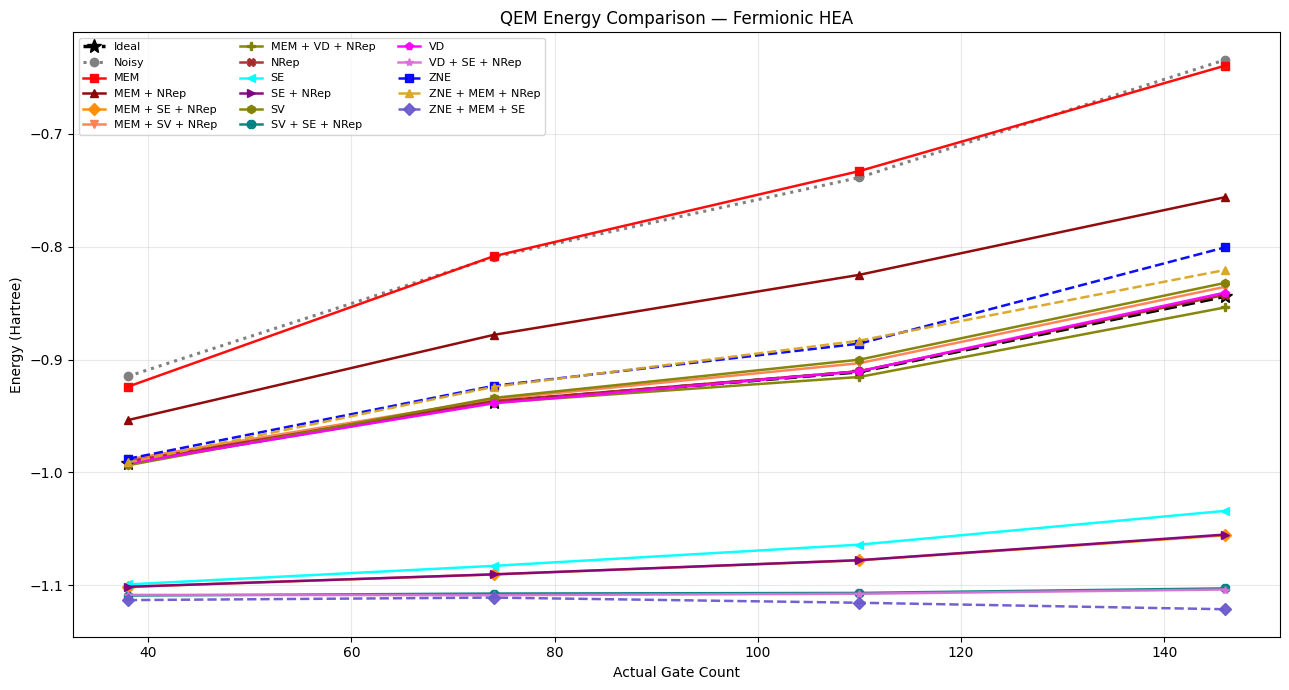

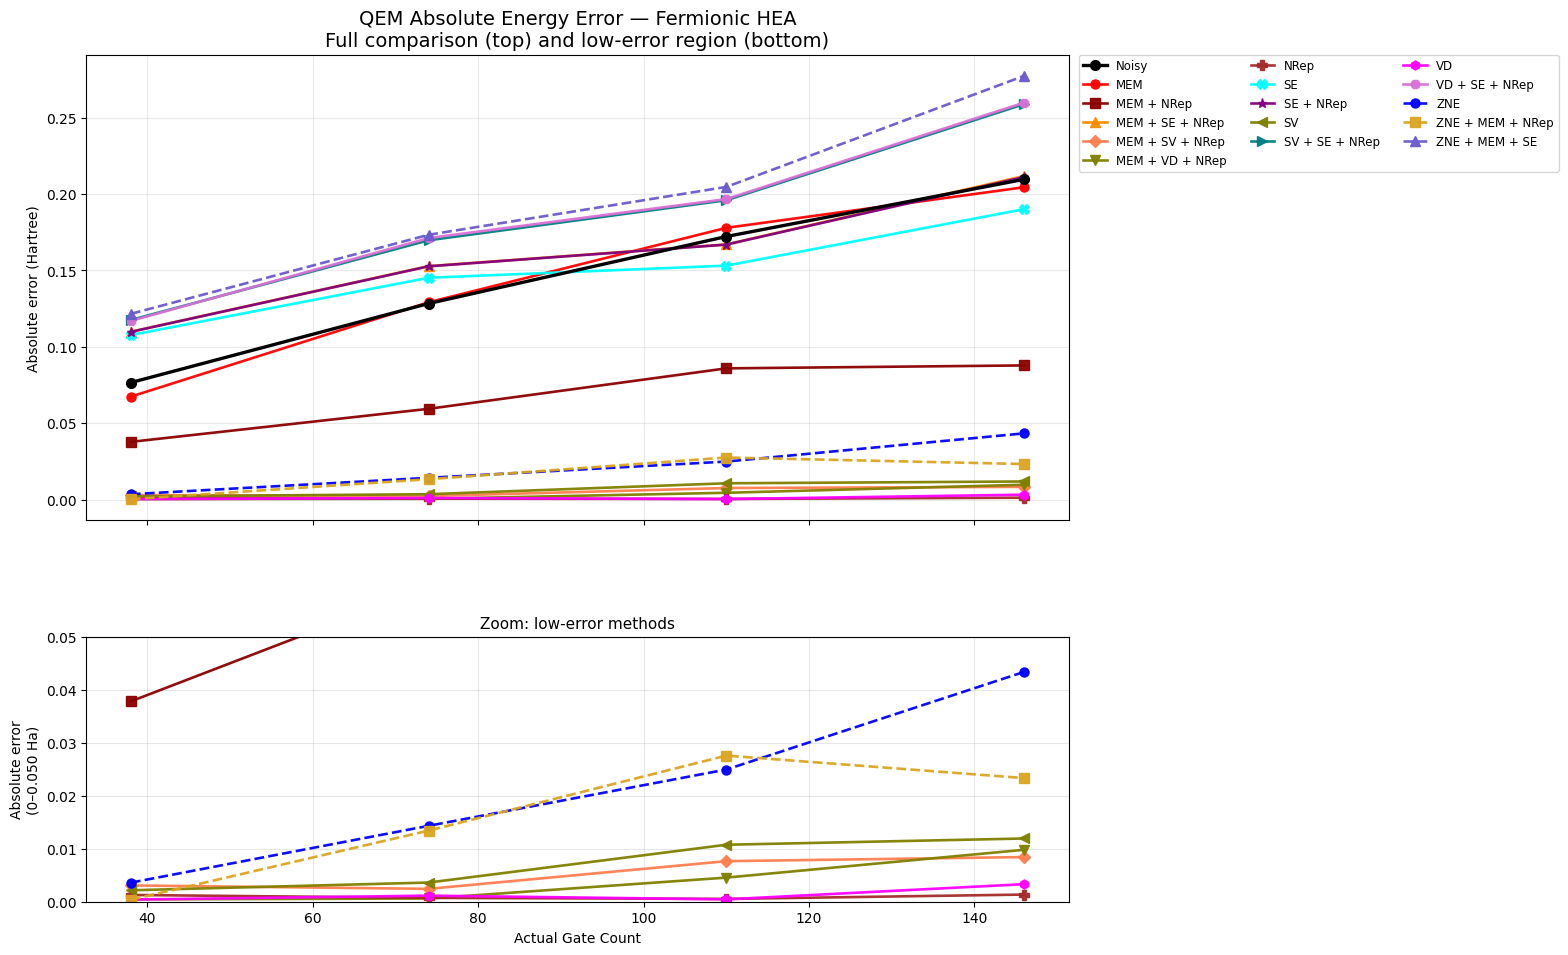


Method ranking by mean absolute energy error:


,Rank,method,mean_abs_error,max_abs_error,depth_count
0,1,NRep,0.000971,0.001352,4
1,2,VD,0.001328,0.003315,4
2,3,MEM + VD + NRep,0.003856,0.009815,4
3,4,MEM + SV + NRep,0.005405,0.008442,4
4,5,SV,0.007125,0.011950,4
5,6,ZNE + MEM + NRep,0.016201,0.027619,4
6,7,ZNE,0.021593,0.043434,4
7,8,MEM + NRep,0.067796,0.087874,4
8,9,MEM,0.144743,0.204437,4
9,10,SE,0.149047,0.190101,4



Lower mean absolute error indicates better average performance over the evaluated HEA depths. Check depth_count to ensure methods are compared over the same number of depths.


In [11]:
def plot_energy(df):
    """
    Plot ideal, noisy, and mitigated energies against actual gate count.
    PEC is displayed without error bars.
    """
    if df.empty:
        print("No successful results to plot.")
        return

    ideal_data = (
        df[["gates", "ideal"]]
        .dropna()
        .drop_duplicates(subset=["gates"])
        .sort_values("gates")
    )

    fig, ax = plt.subplots(figsize=(13, 7))

    if not ideal_data.empty:
        ax.plot(
            ideal_data["gates"], ideal_data["ideal"],
            color="black", linestyle="--", marker="*",
            linewidth=2.5, markersize=10, label="Ideal"
        )

    noisy_data = (
        df[["gates", "noisy"]]
        .dropna()
        .drop_duplicates(subset=["gates"])
        .sort_values("gates")
    )
    if not noisy_data.empty:
        ax.plot(
            noisy_data["gates"], noisy_data["noisy"],
            color="gray", linestyle=":", marker="o",
            linewidth=2.2, markersize=6, label="Noisy"
        )

    methods = list(df["method"].dropna().unique())
    markers = ["s", "^", "D", "v", "P", "X", "<", ">", "h", "8", "p", "*"]
    line_styles = ["-", "--", "-.", ":"]

    for i, method in enumerate(methods):
        d = df[df["method"] == method].dropna(subset=["energy"]).sort_values("gates")
        if d.empty:
            continue
        ax.plot(
            d["gates"], d["energy"],
            color=COLORS.get(method, None),
            linestyle=line_styles[(i // len(markers)) % len(line_styles)],
            marker=markers[i % len(markers)],
            linewidth=1.8, markersize=6,
            label=method, alpha=0.95
        )

    ax.set_xlabel("Actual Gate Count")
    ax.set_ylabel("Energy (Hartree)")
    ax.set_title("QEM Energy Comparison — Fermionic HEA")
    ax.grid(alpha=0.28)
    ax.legend(
        ncol=3, fontsize=8, loc="best",
        frameon=True
    )
    fig.tight_layout()
    fig.savefig("qem_master_energy_comparison.png", dpi=300, bbox_inches="tight")
    plt.show()


def plot_absolute_error(df, zoom_max=0.05):
    """
    Full comparison plus a zoomed panel for low-error methods.
    PEC is shown without error bars.
    """
    if df.empty:
        print("No successful results.")
        return

    raw = (
        df[["gates", "ideal", "noisy"]]
        .dropna()
        .drop_duplicates("gates")
        .sort_values("gates")
    )

    methods = list(df.method.dropna().unique())
    marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "8"]
    line_cycle = ["-", "--", "-.", ":"]

    fig, (ax_full, ax_zoom) = plt.subplots(
        2, 1, figsize=(15, 11), sharex=True,
        gridspec_kw={"height_ratios": [2.2, 1.25]}
    )

    if not raw.empty:
        noisy_error = np.abs(raw.noisy - raw.ideal)
        for ax in (ax_full, ax_zoom):
            ax.plot(
                raw.gates, noisy_error, "ko-",
                label="Noisy", linewidth=2.4, markersize=7,
                zorder=5
            )

    for i, method in enumerate(methods):
        d = df[df.method == method].sort_values("gates")
        errors = np.abs(d.energy - d.ideal)
        style = line_cycle[(i // len(marker_cycle)) % len(line_cycle)]
        marker = marker_cycle[i % len(marker_cycle)]
        color = COLORS.get(method, None)

        for ax in (ax_full, ax_zoom):
            ax.plot(
                d.gates, errors,
                linestyle=style, marker=marker,
                color=color, label=method,
                linewidth=1.9, markersize=6.5,
                alpha=0.95
            )

    ax_full.set_ylabel("Absolute error (Hartree)")
    ax_full.set_title(
        "QEM Absolute Energy Error — Fermionic HEA\n"
        "Full comparison (top) and low-error region (bottom)",
        fontsize=14
    )
    ax_full.grid(alpha=0.28)
    ax_full.legend(
        ncol=3, fontsize=8.5, loc="upper left",
        bbox_to_anchor=(1.01, 1.0), borderaxespad=0
    )

    ax_zoom.set_ylim(0, zoom_max)
    ax_zoom.set_ylabel(f"Absolute error\n(0–{zoom_max:.3f} Ha)")
    ax_zoom.set_xlabel("Actual Gate Count")
    ax_zoom.grid(alpha=0.3)
    ax_zoom.set_title("Zoom: low-error methods", fontsize=11)

    ranking = (
        df.assign(abs_error=np.abs(df.energy - df.ideal))
          .groupby("method", as_index=False)
          .agg(
              mean_abs_error=("abs_error", "mean"),
              max_abs_error=("abs_error", "max"),
              depth_count=("gates", "nunique")
          )
          .sort_values("mean_abs_error")
          .reset_index(drop=True)
    )
    ranking.insert(0, "Rank", np.arange(1, len(ranking) + 1))
    ranking["mean_abs_error"] = ranking["mean_abs_error"].map(
        lambda x: f"{x:.6f}"
    )
    ranking["max_abs_error"] = ranking["max_abs_error"].map(
        lambda x: f"{x:.6f}"
    )

    fig.subplots_adjust(right=0.78, hspace=0.32)
    fig.savefig(
        "qem_master_absolute_error_zoomed.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

    print("\nMethod ranking by mean absolute energy error:")
    display(ranking)
    print(
        "\nLower mean absolute error indicates better average performance "
        "over the evaluated HEA depths. Check depth_count to ensure methods "
        "are compared over the same number of depths."
    )


plot_energy(results_df)
plot_absolute_error(results_df)